In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [7]:
df = pd.read_csv("data/supermarket_sales.csv")

df.head()

,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax,Total,Date,Time,Payment,Rating
0,INV000001,B,Mandalay,Member,Male,Food & Beverages,69.36,3,7.28,119.58,2023-08-08,18:54,Credit card,8.4
1,INV000002,C,Mandalay,Member,Female,Food & Beverages,35.25,1,6.62,137.13,2023-02-09,18:44,Credit card,4.3
2,INV000003,C,Naypyitaw,Normal,Female,Fashion Accessories,57.56,8,4.66,490.48,2023-08-24,16:16,Cash,9.6
3,INV000004,B,Naypyitaw,Member,Female,Food & Beverages,16.60,5,8.57,142.54,2023-02-09,11:35,Cash,4.5
4,INV000005,C,Yangon,Normal,Female,Food & Beverages,49.07,1,3.70,24.43,2023-07-04,8:56,Credit card,5.8


In [8]:
df.shape


(2000, 14)

In [9]:
df.columns.tolist()

['Invoice_ID',
 'Branch',
 'City',
 'Customer_Type',
 'Gender',
 'Product_Line',
 'Unit_Price',
 'Quantity',
 'Tax',
 'Total',
 'Date',
 'Time',
 'Payment',
 'Rating']

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice_ID     2000 non-null   str    
 1   Branch         2000 non-null   str    
 2   City           2000 non-null   str    
 3   Customer_Type  2000 non-null   str    
 4   Gender         2000 non-null   str    
 5   Product_Line   2000 non-null   str    
 6   Unit_Price     2000 non-null   float64
 7   Quantity       2000 non-null   int64  
 8   Tax            2000 non-null   float64
 9   Total          2000 non-null   float64
 10  Date           2000 non-null   str    
 11  Time           2000 non-null   str    
 12  Payment        2000 non-null   str    
 13  Rating         2000 non-null   float64
dtypes: float64(4), int64(1), str(9)
memory usage: 218.9 KB


In [11]:
df.isnull().sum()

Invoice_ID       0
Branch           0
City             0
Customer_Type    0
Gender           0
Product_Line     0
Unit_Price       0
Quantity         0
Tax              0
Total            0
Date             0
Time             0
Payment          0
Rating           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
print("Negative Unit Prices:", (df["Unit_Price"] < 0).sum())
print("Negative Quantities:", (df["Quantity"] < 0).sum())
print("Negative Tax:", (df["Tax"] < 0).sum())
print("Negative Total:", (df["Total"] < 0).sum())

Negative Unit Prices: 0
Negative Quantities: 0
Negative Tax: 0
Negative Total: 0


In [15]:
df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)

datetime64[us]


In [16]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Day_Name"] = df["Date"].dt.day_name()

In [17]:
df[["Date", "Year", "Month", "Month_Name", "Day_Name"]].head()

,Date,Year,Month,Month_Name,Day_Name
0,2023-08-08,2023,8,August,Tuesday
1,2023-02-09,2023,2,February,Thursday
2,2023-08-24,2023,8,August,Thursday
3,2023-02-09,2023,2,February,Thursday
4,2023-07-04,2023,7,July,Tuesday


In [18]:
df["Hour"] = pd.to_datetime(
    df["Time"],
    format="%H:%M"
).dt.hour

In [19]:
df[["Time", "Hour"]].head()

,Time,Hour
0,18:54,18
1,18:44,18
2,16:16,16
3,11:35,11
4,8:56,8


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice_ID     2000 non-null   str           
 1   Branch         2000 non-null   str           
 2   City           2000 non-null   str           
 3   Customer_Type  2000 non-null   str           
 4   Gender         2000 non-null   str           
 5   Product_Line   2000 non-null   str           
 6   Unit_Price     2000 non-null   float64       
 7   Quantity       2000 non-null   int64         
 8   Tax            2000 non-null   float64       
 9   Total          2000 non-null   float64       
 10  Date           2000 non-null   datetime64[us]
 11  Time           2000 non-null   str           
 12  Payment        2000 non-null   str           
 13  Rating         2000 non-null   float64       
 14  Year           2000 non-null   int32         
 15  Month          2000 non-null   i

## 4. Key Performance Indicators (KPIs)

In [23]:
total_sales = df["Total"].sum()
average_transaction = df["Total"].mean()
total_transactions = df["Invoice_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_rating = df["Rating"].mean()

print(f"Total Sales: {total_sales:,.2f}")
print(f"Average Transaction Value: {average_transaction:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Customer Rating: {average_rating:.2f}")

Total Sales: 519,280.69
Average Transaction Value: 259.64
Total Transactions: 2,000
Total Quantity Sold: 10,066
Average Customer Rating: 6.96


In [24]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Average Transaction Value",
        "Total Transactions",
        "Total Quantity Sold",
        "Average Customer Rating"
    ],
    "Value": [
        total_sales,
        average_transaction,
        total_transactions,
        total_quantity,
        average_rating
    ]
})

kpi_summary

,KPI,Value
0,Total Sales,519280.690000
1,Average Transaction Value,259.640345
2,Total Transactions,2000.000000
3,Total Quantity Sold,10066.000000
4,Average Customer Rating,6.957600


## 5. Product Performance Analysis

In [26]:
product_sales = (
    df.groupby("Product_Line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

product_sales

Product_Line
Health & Beauty           96970.32
Sports & Travel           91177.89
Electronic Accessories    88995.19
Home & Lifestyle          86351.63
Food & Beverages          78233.94
Fashion Accessories       77551.72
Name: Total, dtype: float64

In [27]:
product_quantity = (
    df.groupby("Product_Line")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

product_quantity


Product_Line
Health & Beauty           1866
Sports & Travel           1737
Electronic Accessories    1691
Home & Lifestyle          1654
Food & Beverages          1618
Fashion Accessories       1500
Name: Quantity, dtype: int64

In [28]:
product_analysis = df.groupby("Product_Line").agg(
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Quantity_Sold=("Quantity", "sum"),
    Average_Rating=("Rating", "mean"),
    Transactions=("Invoice_ID", "nunique")
).sort_values("Total_Sales", ascending=False)

product_analysis

,Total_Sales,Average_Sale,Quantity_Sold,Average_Rating,Transactions
Product_Line,,,,,
Health & Beauty,96970.32,267.135868,1866,6.991185,363
Sports & Travel,91177.89,259.766068,1737,6.927066,351
Electronic Accessories,88995.19,264.080682,1691,6.862611,337
Home & Lifestyle,86351.63,257.766060,1654,6.972836,335
Food & Beverages,78233.94,250.749808,1618,7.053526,312
Fashion Accessories,77551.72,256.793775,1500,6.942715,302


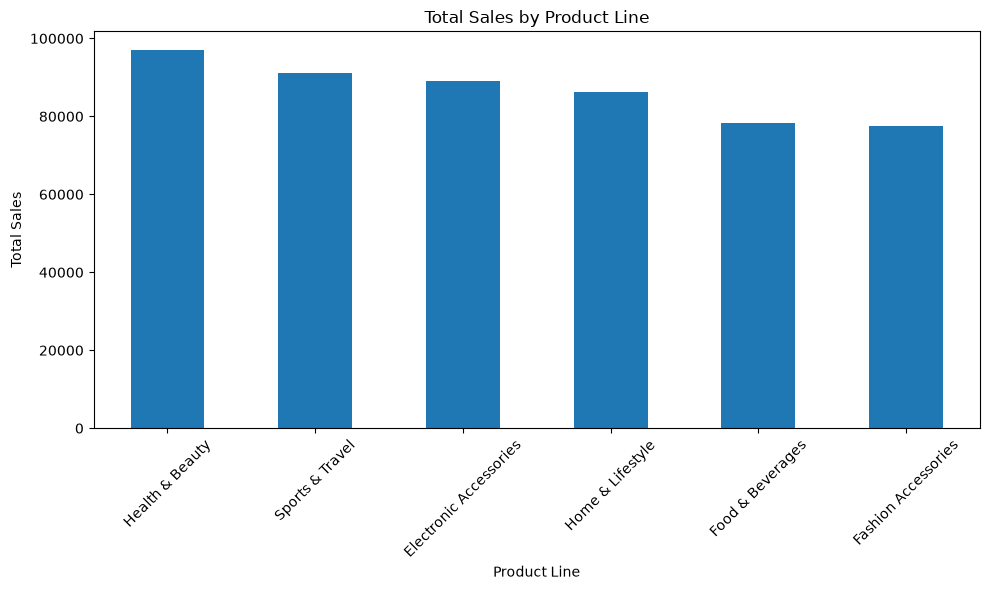

In [29]:
plt.figure(figsize=(10, 6))

product_sales.plot(kind="bar")

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

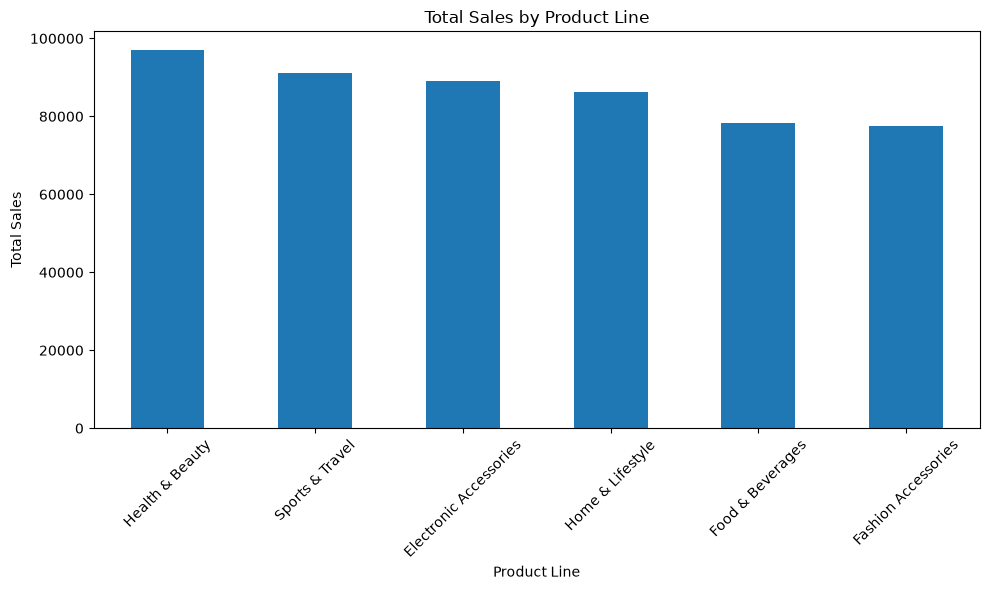

In [31]:
import os

# Create visualizations folder if it doesn't exist
os.makedirs("visualizations", exist_ok=True)

plt.figure(figsize=(10, 6))

product_sales.plot(kind="bar")

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("visualizations/product_sales.png", dpi=300, bbox_inches="tight")

plt.show()


In [32]:
import os

print(os.path.exists("visualizations/product_sales.png"))


True


## 6. Customer Analysis

In [34]:
customer_analysis = df.groupby("Customer_Type").agg(
    Total_Sales=("Total", "sum"),
    Average_Spending=("Total", "mean"),
    Transactions=("Invoice_ID", "nunique"),
    Quantity=("Quantity", "sum"),
    Average_Rating=("Rating", "mean")
)

customer_analysis

,Total_Sales,Average_Spending,Transactions,Quantity,Average_Rating
Customer_Type,,,,,
Member,261919.34,257.288153,1018,5094,6.945383
Normal,257361.35,262.078768,982,4972,6.970265


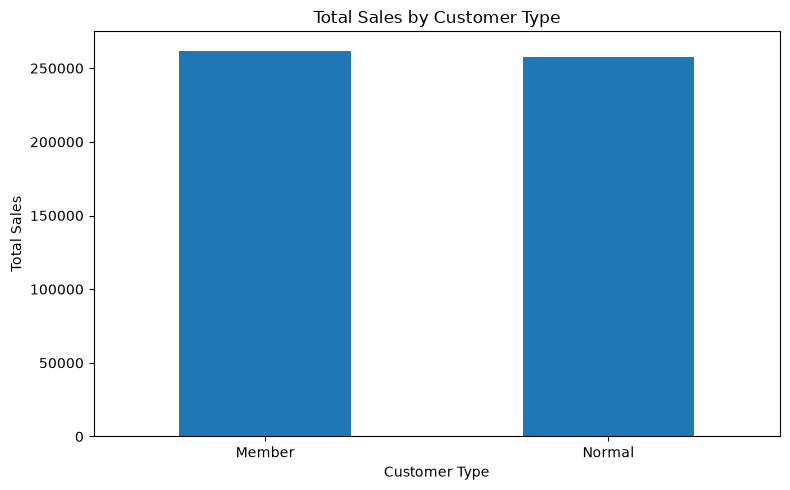

In [35]:
customer_sales = (
    df.groupby("Customer_Type")["Total"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

customer_sales.plot(kind="bar")

plt.title("Total Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("visualizations/customer_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [36]:
import os
print(os.path.exists("visualizations/customer_sales.png"))

True


In [37]:
branch_analysis = df.groupby("Branch").agg(
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Transactions=("Invoice_ID", "nunique"),
    Quantity=("Quantity", "sum")
).sort_values("Total_Sales", ascending=False)

branch_analysis

,Total_Sales,Average_Sale,Transactions,Quantity
Branch,,,,
B,180821.79,259.801422,696,3458
A,179047.93,265.649748,674,3362
C,159410.97,253.033286,630,3246


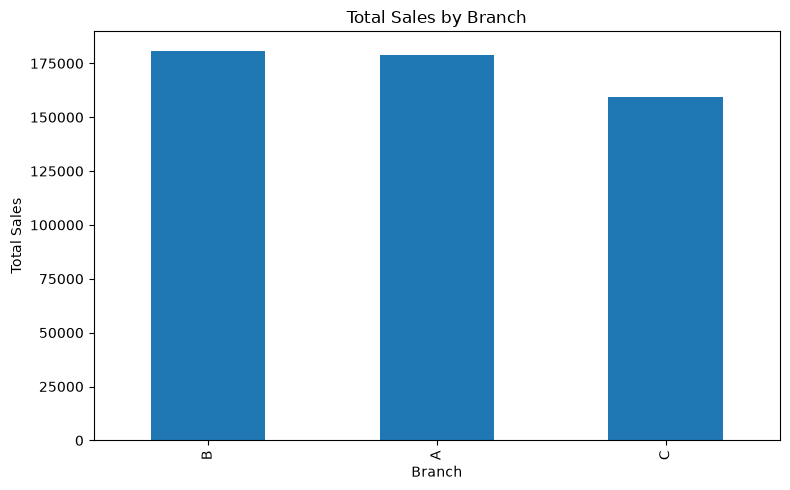

In [38]:
branch_sales = (
    df.groupby("Branch")["Total"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

branch_sales.plot(kind="bar")

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig("visualizations/branch_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [39]:
print(os.path.exists("visualizations/branch_sales.png"))

True


## 8. Time-Based Sales Analysis

In [40]:
daily_sales = df.groupby("Date")["Total"].sum()

daily_sales.head()

Date
2023-01-01    1145.28
2023-01-02    1631.56
2023-01-03     775.06
2023-01-04    1285.96
2023-01-05     176.61
Name: Total, dtype: float64

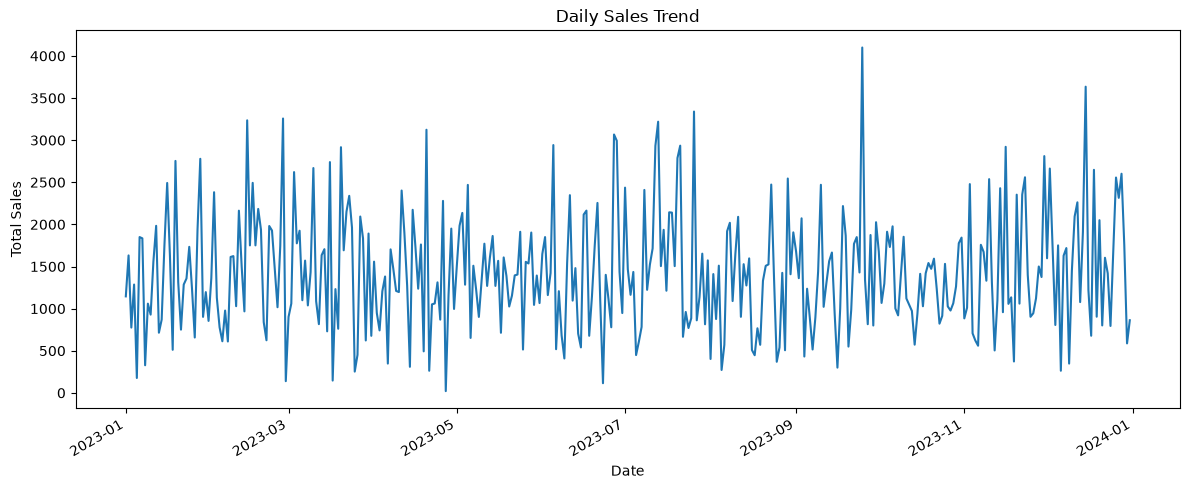

In [41]:
plt.figure(figsize=(12, 5))

daily_sales.plot()

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig("visualizations/daily_sales_trend.png", dpi=300, bbox_inches="tight")

plt.show()

In [42]:
day_sales = (
    df.groupby("Day_Name")["Total"]
    .sum()
    .sort_values(ascending=False)
)

day_sales

Day_Name
Thursday     79450.41
Tuesday      78794.03
Monday       77375.22
Friday       75184.93
Wednesday    74979.62
Saturday     68889.41
Sunday       64607.07
Name: Total, dtype: float64

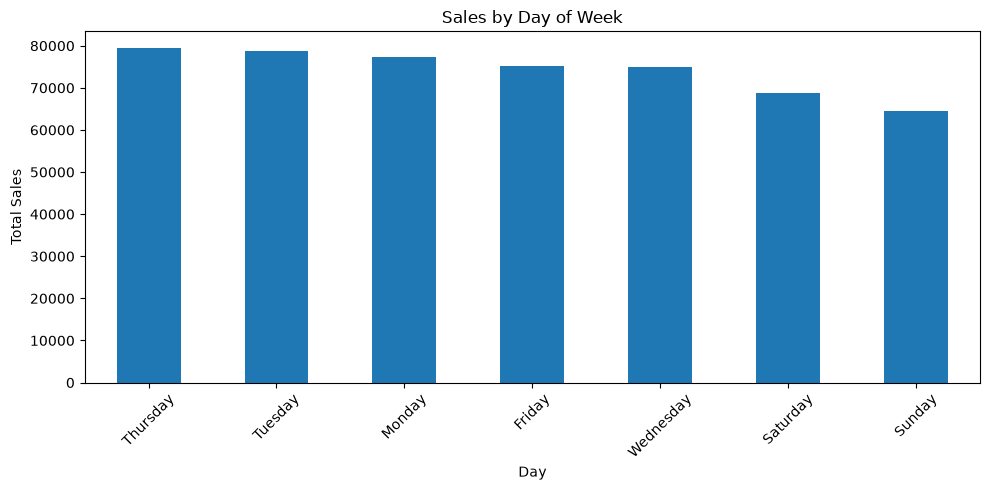

In [43]:
plt.figure(figsize=(10, 5))

day_sales.plot(kind="bar")

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("visualizations/day_of_week_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [44]:
best_sales_day = daily_sales.idxmax()
best_sales_value = daily_sales.max()

worst_sales_day = daily_sales.idxmin()
worst_sales_value = daily_sales.min()

print("Best Sales Day:", best_sales_day)
print(f"Best Sales Value: {best_sales_value:,.2f}")

print("Worst Sales Day:", worst_sales_day)
print(f"Worst Sales Value: {worst_sales_value:,.2f}")

Best Sales Day: 2023-09-25 00:00:00
Best Sales Value: 4,099.76
Worst Sales Day: 2023-04-27 00:00:00
Worst Sales Value: 20.63


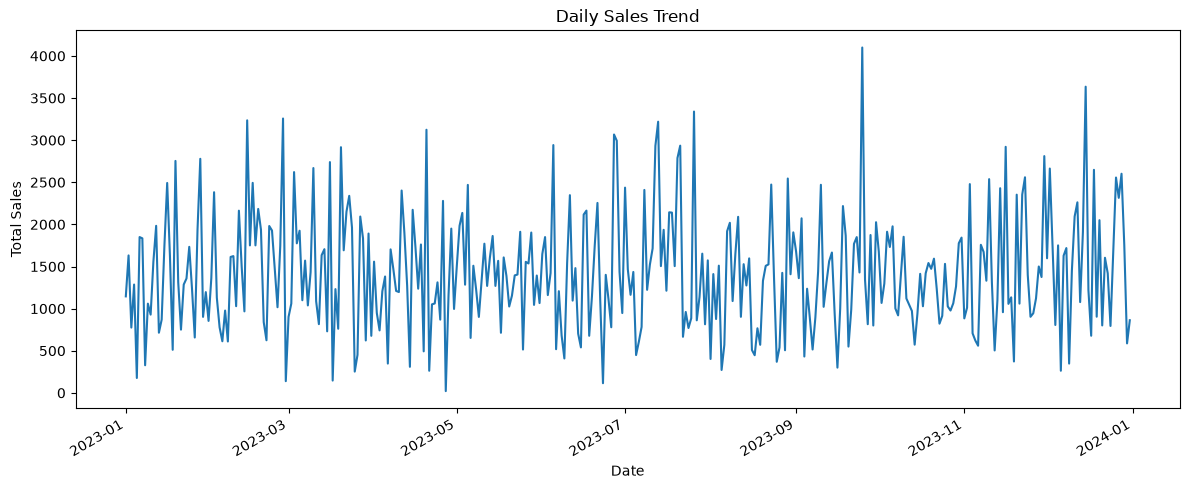

In [45]:
plt.figure(figsize=(12, 5))

daily_sales.plot()

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig("visualizations/daily_sales_trend.png", dpi=300, bbox_inches="tight")

plt.show()

In [46]:
print(os.path.exists("visualizations/daily_sales_trend.png"))

True


In [49]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = (
    df.groupby("Day_Name")["Total"]
    .sum()
    .reindex(day_order)
)

day_sales

Day_Name
Monday       77375.22
Tuesday      78794.03
Wednesday    74979.62
Thursday     79450.41
Friday       75184.93
Saturday     68889.41
Sunday       64607.07
Name: Total, dtype: float64

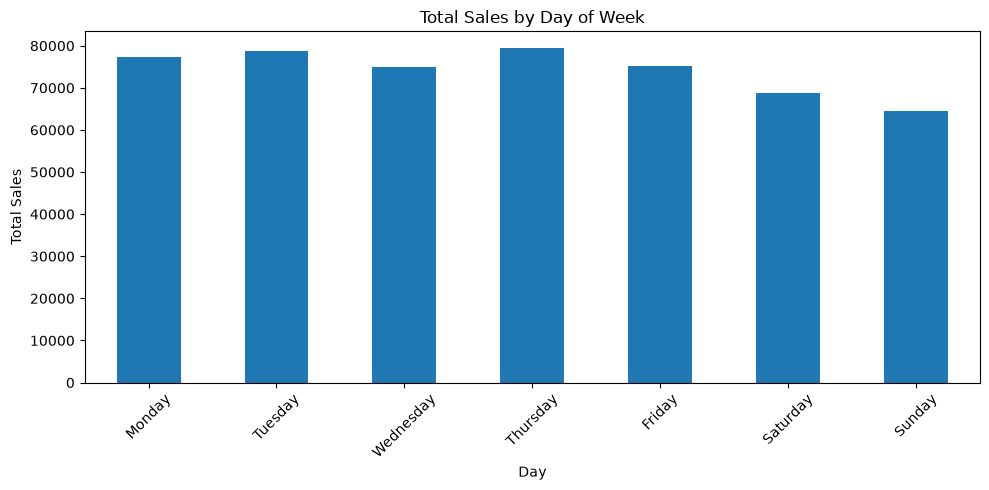

In [50]:
plt.figure(figsize=(10, 5))

day_sales.plot(kind="bar")

plt.title("Total Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "visualizations/day_of_week_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
best_day = day_sales.idxmax()
best_day_sales = day_sales.max()

worst_day = day_sales.idxmin()
worst_day_sales = day_sales.min()

print("Best Day of Week:", best_day)
print(f"Sales: {best_day_sales:,.2f}")

print("Lowest Day of Week:", worst_day)
print(f"Sales: {worst_day_sales:,.2f}")

Best Day of Week: Thursday
Sales: 79,450.41
Lowest Day of Week: Sunday
Sales: 64,607.07


In [52]:
day_sales


Day_Name
Monday       77375.22
Tuesday      78794.03
Wednesday    74979.62
Thursday     79450.41
Friday       75184.93
Saturday     68889.41
Sunday       64607.07
Name: Total, dtype: float64

In [53]:
average_daily_sales = day_sales.mean()

sales_difference = best_day_sales - worst_day_sales

print(f"Average Sales per Day of Week: {average_daily_sales:,.2f}")
print(f"Difference Between Best and Worst Day: {sales_difference:,.2f}")

Average Sales per Day of Week: 74,182.96
Difference Between Best and Worst Day: 14,843.34


In [54]:
day_sales_percentage = (day_sales / day_sales.sum()) * 100

day_sales_percentage

Day_Name
Monday       14.900462
Tuesday      15.173688
Wednesday    14.439131
Thursday     15.300089
Friday       14.478669
Saturday     13.266315
Sunday       12.441647
Name: Total, dtype: float64

### Weekday Sales Insights

Thursday recorded the highest total sales at ₹79,450.41, while
Sunday recorded the lowest sales at ₹64,607.07.

Sales were generally stronger from Monday through Friday, while
Saturday and Sunday showed lower sales levels. The difference
between Thursday and Sunday was ₹14,843.34.

This pattern suggests that weekday promotional campaigns and
inventory planning may be more important than weekend-focused
strategies.

In [55]:
hour_sales = (
    df.groupby("Hour")["Total"]
    .sum()
    .sort_values(ascending=False)
)

hour_sales

Hour
18    48286.93
14    47755.79
8     46916.15
12    44961.17
13    44157.11
10    43841.17
17    42999.17
16    41660.57
9     41167.07
19    41025.93
15    39165.24
11    37344.39
Name: Total, dtype: float64

In [58]:
peak_hour = hour_sales.idxmax()
peak_hour_sales = hour_sales.max()

lowest_hour = hour_sales.idxmin()
lowest_hour_sales = hour_sales.min()

print("Peak Sales Hour:", peak_hour)
print(f"Peak Hour Sales: ₹{peak_hour_sales:,.2f}")

print("Lowest Sales Hour:", lowest_hour)
print(f"Lowest Hour Sales: ₹{lowest_hour_sales:,.2f}")

Peak Sales Hour: 18
Peak Hour Sales: ₹48,286.93
Lowest Sales Hour: 11
Lowest Hour Sales: ₹37,344.39


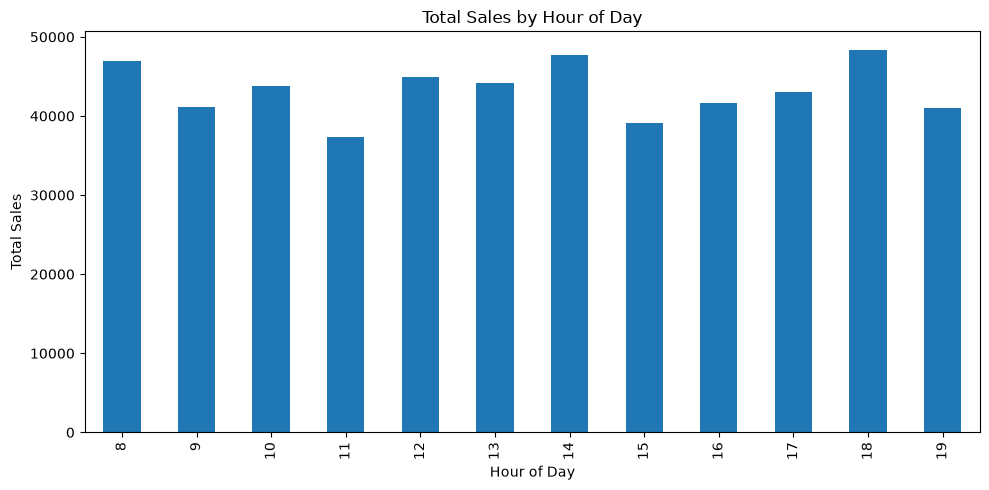

Saved to: C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\hourly_sales.png
File exists: True


In [60]:
import os

os.makedirs("visualizations", exist_ok=True)

plt.figure(figsize=(10, 5))

hour_sales.sort_index().plot(kind="bar")

plt.title("Total Sales by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Total Sales")

plt.tight_layout()

file_path = os.path.abspath("visualizations/hourly_sales.png")

plt.savefig(file_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved to:", file_path)
print("File exists:", os.path.exists(file_path))


## 9. Statistical Analysis

In [61]:
statistics = df[
    ["Unit_Price", "Quantity", "Tax", "Total", "Rating"]
].describe()

statistics

,Unit_Price,Quantity,Tax,Total,Rating
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000
mean,55.258490,5.0330,5.512745,259.640345,6.957600
std,25.813536,2.6087,2.582829,138.930861,1.730534
min,10.010000,1.0000,1.000000,20.370000,4.000000
25%,33.615000,3.0000,3.317500,137.872500,5.400000
50%,55.610000,5.0000,5.440000,258.040000,6.950000
75%,77.500000,7.0000,7.742500,386.937500,8.400000
max,99.920000,9.0000,10.000000,499.910000,10.000000


In [62]:
mean_values = df[
    ["Unit_Price", "Quantity", "Tax", "Total", "Rating"]
].mean()

median_values = df[
    ["Unit_Price", "Quantity", "Tax", "Total", "Rating"]
].median()

print("MEAN")
print(mean_values)

print("\nMEDIAN")
print(median_values)

MEAN
Unit_Price     55.258490
Quantity        5.033000
Tax             5.512745
Total         259.640345
Rating          6.957600
dtype: float64

MEDIAN
Unit_Price     55.61
Quantity        5.00
Tax             5.44
Total         258.04
Rating          6.95
dtype: float64


## 10. Correlation Analysis

In [63]:
correlation = df[
    ["Unit_Price", "Quantity", "Tax", "Total", "Rating"]
].corr()

correlation

,Unit_Price,Quantity,Tax,Total,Rating
Unit_Price,1.000000,0.021547,-0.006407,0.004670,-0.013828
Quantity,0.021547,1.000000,-0.021480,-0.012459,-0.015680
Tax,-0.006407,-0.021480,1.000000,-0.004217,-0.016355
Total,0.004670,-0.012459,-0.004217,1.000000,-0.009223
Rating,-0.013828,-0.015680,-0.016355,-0.009223,1.000000


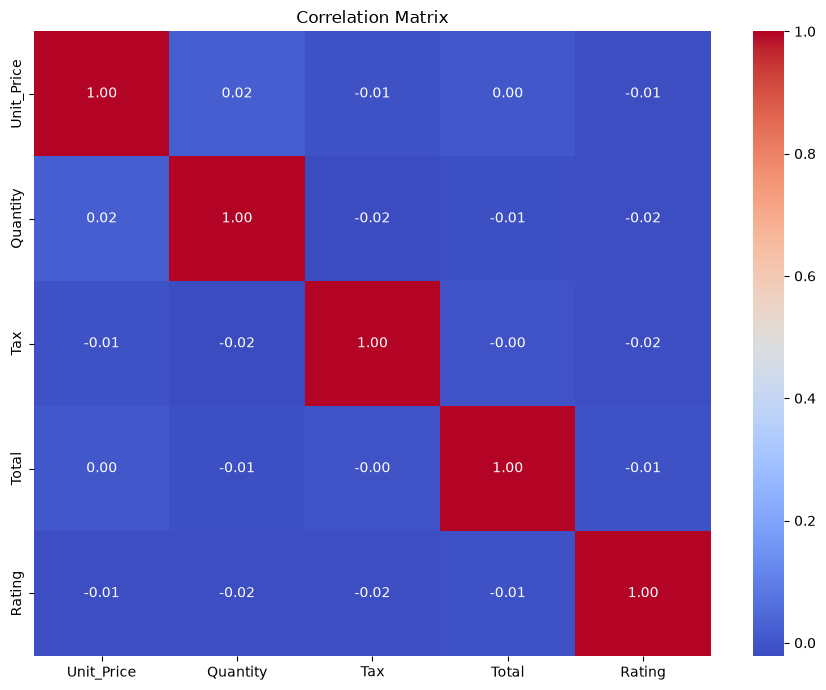

In [64]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.savefig(
    "visualizations/correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
print(os.path.exists("visualizations/correlation_matrix.png"))

True


## 11. Business Insights

### 1. Product Performance

Health & Beauty generated the highest total sales at ₹96,970.32,
with 1,866 units sold across 363 transactions.

Fashion Accessories generated the lowest total sales at
₹77,551.72, with 1,500 units sold across 302 transactions.

This indicates that Health & Beauty was the strongest-performing
product line in the analyzed dataset, while Fashion Accessories
may require further investigation.

### 2. Customer Performance

Member and Normal customers generated similar overall sales,
with Member customers contributing slightly higher sales.

This suggests that both customer segments are important to the
business and should be considered in promotional and retention
strategies.

### 3. Branch Performance

Branch B generated the highest total sales at ₹180,821.79 from
696 transactions.

Branch C generated the lowest total sales at ₹159,410.97 from
630 transactions.

Branch-level differences suggest that Branch C could be studied
further to identify opportunities for improving sales and customer
traffic.

### 4. Weekly Sales Pattern

Thursday recorded the highest sales among the days of the week,
with ₹79,450.41.

Sunday recorded the lowest sales, with ₹64,607.07.

The difference between the highest and lowest day was
₹14,843.34, indicating variation in sales performance throughout
the week.

### 5. Hourly Sales Pattern

6 PM recorded the highest hourly sales at ₹48,286.93.

11 AM recorded the lowest hourly sales at ₹37,344.39.

The evening period therefore represents an important sales period
within the analyzed dataset.

### 6. Statistical Findings

The average transaction value was ₹259.64, while the median
transaction value was ₹258.04.

The mean customer rating was 6.96 and the median rating was 6.95.

The correlation analysis showed very weak relationships between
the numerical variables analyzed. Therefore, no strong linear
relationship was identified between transaction total and the
other selected numerical variables.

## 12. Business Recommendations

### 1. Strengthen High-Performing Product Lines

Maintain sufficient inventory for Health & Beauty products because
this category generated the highest sales in the analyzed dataset.

### 2. Investigate Lower-Performing Products

Analyze Fashion Accessories to understand whether pricing,
product selection, promotions, or customer demand are contributing
to its lower sales performance.

### 3. Improve Branch C Performance

Compare Branch C with Branch B to identify differences in product
mix, transaction volume, customer behavior, and operational
performance.

### 4. Optimize Staffing Around Peak Hours

Ensure sufficient staff and product availability around the
6 PM peak sales period.

### 5. Use Day-Based Promotions

Consider targeted promotions during lower-performing periods,
particularly Sunday, to encourage additional customer traffic.

### 6. Continue Monitoring Customer Segments

Since Member and Normal customers contribute similar sales,
marketing strategies should address both segments rather than
focusing exclusively on one group.

### 7. Use Data for Continuous Monitoring

Repeat this analysis regularly to identify changes in product,
branch, customer, and time-based sales patterns.

# Executive Summary

This project analyzes 2,000 supermarket transactions to understand
sales performance, product performance, customer behavior, branch
performance, and time-based sales patterns.

Health & Beauty was the highest-performing product line, generating
₹96,970.32 in sales, while Fashion Accessories generated the lowest
sales at ₹77,551.72.

At the branch level, Branch B recorded the highest sales at
₹180,821.79, while Branch C recorded the lowest at ₹159,410.97.

Thursday was the strongest sales day with ₹79,450.41, while Sunday
recorded the lowest sales at ₹64,607.07. The highest hourly sales
occurred at 6 PM, with ₹48,286.93.

Statistical analysis showed an average transaction value of ₹259.64
and a median transaction value of ₹258.04. The correlation analysis
showed very weak linear relationships among the selected numerical
variables.

The analysis recommends focusing on high-performing product
inventory, investigating lower-performing categories and branches,
optimizing staffing around peak hours, and using targeted
promotions during weaker sales periods.


## 13. Conclusion

The supermarket sales analysis provided an end-to-end examination
of transaction data using Python, Pandas, NumPy, Matplotlib, and
Seaborn.

The project demonstrated data loading, data cleaning, validation,
transformation, exploratory data analysis, statistical analysis,
data visualization, and business insight generation.

The analysis identified important differences across product
lines, branches, customer segments, weekdays, and sales hours.

These findings can support inventory planning, promotional
strategies, staffing decisions, branch performance evaluation,
and future customer analytics.